In [1]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261019


In [3]:
df = pd.read_pickle(f"../datasets/Processed/Averages_gChirpFieldsFiltered_20261013.pkl")
df.shape

(3784, 48)

In [4]:
sum(df["cluster_gchirp"].value_counts().sort_index() / 2)

1537.0

In [5]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c2 = df[df_idx.isin(c2_groups)]
df_detano = df[df_idx.isin(detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


# C1/C2

In [6]:
print(df_c2.shape)
print(sum(df_c2["cluster_gchirp"].value_counts().sort_index() / 2))

(1858, 48)
841.0


In [7]:
df_cluster0 = df_c2[df_c2["cluster_gchirp"] == 0]
print(df_cluster0.shape)

(336, 48)


In [8]:
df_c1_cluster0 = df_cluster0[df_cluster0["cond2"] == "C1"]
df_c2_cluster0 = df_cluster0[df_cluster0["cond2"] == "C2"]

print(df_c1_cluster0.shape)
print(df_c2_cluster0.shape)

(168, 48)
(168, 48)


In [9]:
sf = 500  # sampling frequency (Hz)

features = {
    "on":        [round(sf*2),  round(sf*5)],
    "off":       [round(sf*5),  round(sf*8)],
    "low_freq":  [round(sf*10), round(sf*13)],
    "high_freq": [round(sf*15), round(sf*18)],
    "low_cont":  [round(sf*20), round(sf*23)],
    "high_cont": [round(sf*25), round(sf*28)],
}

trace_col = "average_norm_gChirp"

In [10]:
max_end = max(end for _, end in features.values())

len_c1 = df_c1_cluster0[trace_col].apply(lambda x: len(np.asarray(x)))
len_c2 = df_c2_cluster0[trace_col].apply(lambda x: len(np.asarray(x)))

print("C1 trace lengths:", len_c1.unique())
print("C2 trace lengths:", len_c2.unique())
print("Required length (max window end):", max_end)

too_short = (len_c1 < max_end) | (len_c2 < max_end)
print(f"ROIs with traces too short: {too_short.sum()}")

C1 trace lengths: [16516]
C2 trace lengths: [16516]
Required length (max window end): 14000
ROIs with traces too short: 0


In [11]:
def safe_corr(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if len(a) != len(b) or len(a) < 2:
        return np.nan
    mask = ~np.isnan(a) & ~np.isnan(b)
    a, b = a[mask], b[mask]
    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def feature_correlations(trace0, trace1, features):
    trace0 = np.asarray(trace0, dtype=float)
    trace1 = np.asarray(trace1, dtype=float)
    return {name: safe_corr(trace0[start:end], trace1[start:end])
            for name, (start, end) in features.items()}

In [12]:
roi_id_col = None

key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

# If roi_id was moved into the index in Cell 2, bring it back as a column
c1_k = df_c1_cluster0.reset_index() if roi_id_col is not None else df_c1_cluster0
c2_k = df_c2_cluster0.reset_index() if roi_id_col is not None else df_c2_cluster0

missing = [k for k in key_cols if k not in c1_k.columns or k not in c2_k.columns]
assert not missing, f"Missing key columns: {missing}"

# Keys that are identical in both dataframes for every ROI are stored once;
# keys that differ are stored as <key>_c1 and <key>_c2
differing = [k for k in key_cols
             if not (c1_k[k].astype(str).values == c2_k[k].astype(str).values).all()]
shared = [k for k in key_cols if k not in differing]
print("Shared keys:   ", shared)
print("Differing keys:", differing)

results = []
for i in range(len(c1_k)):
    row1 = c1_k.iloc[i]
    row2 = c2_k.iloc[i]

    rec = {k: row1[k] for k in shared}
    for k in differing:
        rec[f"{k}_c1"] = row1[k]
        rec[f"{k}_c2"] = row2[k]

    rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
    results.append(rec)

index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
df_corr = pd.DataFrame(results).set_index(index_cols)
df_corr_flat = df_corr.reset_index()

assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
df_corr_flat.head()

Shared keys:    ['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp']
Differing keys: []


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY7,RR,n,3,0.0,0.784835,0.462281,0.753795,0.400329,0.057516,0.453642
1,Salomon,2025-09-08,2,1,XY7,RR,n,5,0.0,0.883242,0.578496,0.859612,0.144386,0.274412,0.306527
2,Salomon,2025-09-08,2,1,XY7,RR,n,6,0.0,0.823055,0.738074,0.851499,0.099752,0.051668,0.187336
3,Salomon,2025-09-08,2,1,XY7,RR,n,8,0.0,0.812928,-0.045439,0.549846,0.494214,0.580300,0.453778
4,Salomon,2025-09-08,2,1,XY7,RR,n,9,0.0,0.766792,-0.083728,0.893611,-0.442164,0.086516,0.452096


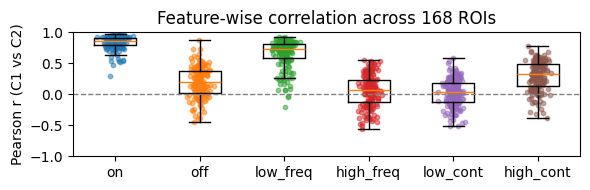

In [13]:
fig, ax = plt.subplots(figsize=(6, 2))

data = [df_corr[f].dropna().values for f in features]
ax.boxplot(data, tick_labels=list(features), showfliers=False)

for i, d in enumerate(data, start=1):
    jitter = np.random.normal(0, 0.06, size=len(d))
    ax.scatter(np.full(len(d), i) + jitter, d, s=10, alpha=0.5)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Pearson r (C1 vs C2)")
ax.set_title(f"Feature-wise correlation across {len(df_corr)} ROIs")
ax.set_ylim(-1,1)
plt.tight_layout()
plt.show()

In [14]:
cluster_ids = df["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


In [15]:
n_rois_c1 = []
n_rois_c2 = []

for i in cluster_ids:

    df_cluster = df_c2[df_c2["cluster_gchirp"] == i]

    #n_rois.append(df_cluster.shape[0] / 2)

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_c2_cluster = df_cluster[df_cluster["cond2"] == "C2"]

    n_rois_c1.append(df_c1_cluster.shape[0])
    n_rois_c2.append(df_c2_cluster.shape[0])
    
print(sum(n_rois_c1))
print(sum(n_rois_c2))

841
841


In [16]:
corr_list = []

for i in cluster_ids:

    df_cluster = df_c2[df_c2["cluster_gchirp"] == i]

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_c2_cluster = df_cluster[df_cluster["cond2"] == "C2"]

    max_end = max(end for _, end in features.values())

    len_c1 = df_c1_cluster[trace_col].apply(lambda x: len(np.asarray(x)))
    len_c2 = df_c2_cluster[trace_col].apply(lambda x: len(np.asarray(x)))

    too_short = (len_c1 < max_end) | (len_c2 < max_end)

    if too_short.sum() > 0:
        raise ValueError("One of the traces is too short")

    key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

    # If roi_id was moved into the index in Cell 2, bring it back as a column
    c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
    c2_k = df_c2_cluster.reset_index() if roi_id_col is not None else df_c2_cluster
    
    missing = [k for k in key_cols if k not in c1_k.columns or k not in c2_k.columns]
    assert not missing, f"Missing key columns: {missing}"
    
    # Keys that are identical in both dataframes for every ROI are stored once;
    # keys that differ are stored as <key>_c1 and <key>_c2
    differing = [k for k in key_cols
                 if not (c1_k[k].astype(str).values == c2_k[k].astype(str).values).all()]
    shared = [k for k in key_cols if k not in differing]
    # print("Shared keys:   ", shared)
    # print("Differing keys:", differing)
    
    results = []
    for j in range(len(c1_k)):
        row1 = c1_k.iloc[j]
        row2 = c2_k.iloc[j]
    
        rec = {k: row1[k] for k in shared}
        for k in differing:
            rec[f"{k}_c1"] = row1[k]
            rec[f"{k}_c2"] = row2[k]
    
        rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
        results.append(rec)
    
    index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
    df_corr = pd.DataFrame(results).set_index(index_cols)
    df_corr_flat = df_corr.reset_index()
    
    assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
    df_corr_flat.head()

    corr_list.append(df_corr_flat)
df_correlation = pd.concat(corr_list, ignore_index=True)

In [17]:
df_correlation.shape

(841, 15)

In [18]:
df_correlation["cluster_gchirp"].value_counts().sort_index()

cluster_gchirp
0.0    168
1.0    109
2.0     75
3.0    183
4.0     27
5.0     83
6.0    153
7.0     43
Name: count, dtype: int64

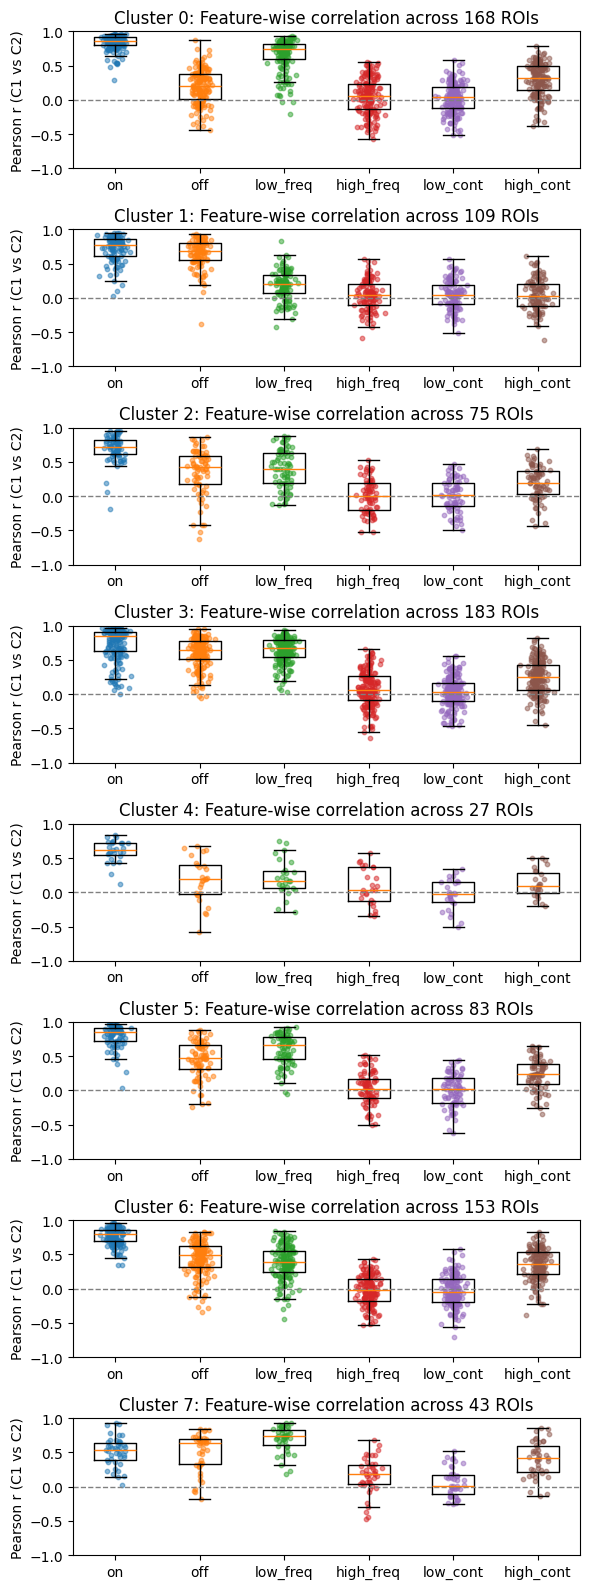

In [19]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(6, 2 * n_clusters))

for i in cluster_ids:

    df_correlation_cluster = df_correlation[df_correlation["cluster_gchirp"] == i]

    data = [df_correlation_cluster[f].dropna().values for f in features]
    axs[i].boxplot(data, tick_labels=list(features), showfliers=False)
    
    for j, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.06, size=len(d))
        axs[i].scatter(np.full(len(d), j) + jitter, d, s=10, alpha=0.5)
    
    axs[i].axhline(0, color="grey", linestyle="--", linewidth=1)
    axs[i].set_ylabel("Pearson r (C1 vs C2)")
    axs[i].set_title(f"Cluster {i}: Feature-wise correlation across {len(df_correlation_cluster)} ROIs")
    axs[i].set_ylim(-1,1)

plt.tight_layout()
# plt.savefig(f"../plots/clustering/feature_correlations_boxplot_{current_date}.png",
#             dpi=300,
#             bbox_inches="tight")
plt.show()

In [20]:
df_correlation_cluster0 = df_correlation[df_correlation["cluster_gchirp"] == 0]
print(df_correlation_cluster0.shape)

(168, 15)


In [21]:
print(df_correlation_cluster0.columns.to_list())

['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp', 'on', 'off', 'low_freq', 'high_freq', 'low_cont', 'high_cont']


In [22]:
columns = ["cluster_gchirp", "on", "off", "low_freq", "high_freq", "low_cont", "high_cont"]
columns

['cluster_gchirp',
 'on',
 'off',
 'low_freq',
 'high_freq',
 'low_cont',
 'high_cont']

In [23]:
mean_corr_cluster0 = df_correlation_cluster0[columns].mean(axis=0)
std_corr_cluster0 = df_correlation_cluster0[columns].std(axis=0)

print(mean_corr_cluster0)
print(std_corr_cluster0)

cluster_gchirp    0.000000
on                0.835199
off               0.196062
low_freq          0.660619
high_freq         0.053445
low_cont          0.022269
high_cont         0.301533
dtype: float64
cluster_gchirp    0.000000
on                0.103866
off               0.245354
low_freq          0.227562
high_freq         0.259180
low_cont          0.219710
high_cont         0.236009
dtype: float64


In [24]:
# Convert to a DataFrame with one row
heatmap_mean = pd.DataFrame(
    [mean_corr_cluster0.values],
    columns=columns,
    index=["Cluster 0"]
)

heatmap_std = pd.DataFrame(
    [std_corr_cluster0.values],
    columns=columns,
    index=["Cluster 0"]
)

print(heatmap_mean.shape)
print(heatmap_std.shape)

(1, 7)
(1, 7)


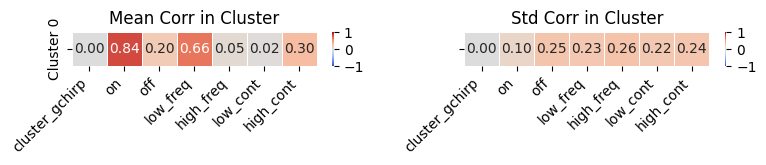

In [25]:
# Plot heatmap
fig, axs = plt.subplots(1, 2, figsize=(8, 1.75), sharey=True)

sns.heatmap(
    heatmap_mean,
    ax=axs[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

sns.heatmap(
    heatmap_std,
    ax=axs[1],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar=True
)

for i in axs:
    i.set_xlabel("")
    i.set_ylabel("")
    i.set_xticklabels(i.get_xticklabels(), rotation=45, ha="right")

axs[0].set_title("Mean Corr in Cluster")
axs[1].set_title("Std Corr in Cluster")

plt.tight_layout()
plt.show()

In [26]:
# # Plot heatmaps
# fig, axs = plt.subplots(
#     n_clusters, 2,
#     figsize=(8, 1 * n_clusters),
#     sharex=True,
#     sharey=True,
#     squeeze=False
# )

mean_correlation = []
std_correlation = []

for row, i in enumerate(cluster_ids):

    df_correlation_cluster = df_correlation[
        df_correlation["cluster_gchirp"] == i
    ]

    mean_corr_cluster = df_correlation_cluster[columns].mean(axis=0)
    std_corr_cluster = df_correlation_cluster[columns].std(axis=0)

    # Convert to DataFrames with one row
    heatmap_mean_cluster = pd.DataFrame(
        [mean_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    heatmap_std_cluster = pd.DataFrame(
        [std_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    mean_correlation.append(heatmap_mean_cluster)
    std_correlation.append(heatmap_std_cluster)

df_mean_correlation = pd.concat(mean_correlation)
df_mean_correlation = df_mean_correlation.reset_index(drop=True)

df_std_correlation = pd.concat(std_correlation)
df_std_correlation = df_std_correlation.reset_index(drop=True)


#     # Mean correlation heatmap
#     sns.heatmap(
#         heatmap_mean_cluster,
#         ax=axs[row, 0],
#         cmap="coolwarm",
#         vmin=-1,
#         vmax=1,
#         center=0,
#         annot=True,
#         fmt=".2f",
#         linewidths=0.5
#     )

#     # Standard deviation heatmap
#     sns.heatmap(
#         heatmap_std_cluster,
#         ax=axs[row, 1],
#         cmap="coolwarm",
#         vmin=-1,
#         vmax=1,
#         center=0,
#         annot=True,
#         fmt=".2f",
#         linewidths=0.5,
#         cbar=True
#     )

# plt.tight_layout()
# plt.show()

In [27]:
df_std_correlation

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.103866,0.245354,0.227562,0.259180,0.219710,0.236009
1,0.0,0.190716,0.206584,0.216422,0.222719,0.215113,0.232240
2,0.0,0.193985,0.333906,0.280391,0.244075,0.235058,0.242583
3,0.0,0.235594,0.221836,0.184883,0.257697,0.217697,0.241970
4,0.0,0.165638,0.321127,0.262160,0.271295,0.225861,0.204195
5,0.0,0.167792,0.262674,0.222020,0.238960,0.234784,0.225439
6,0.0,0.123121,0.248760,0.249126,0.214326,0.230913,0.225230
7,0.0,0.207931,0.276751,0.182159,0.262194,0.208155,0.254099


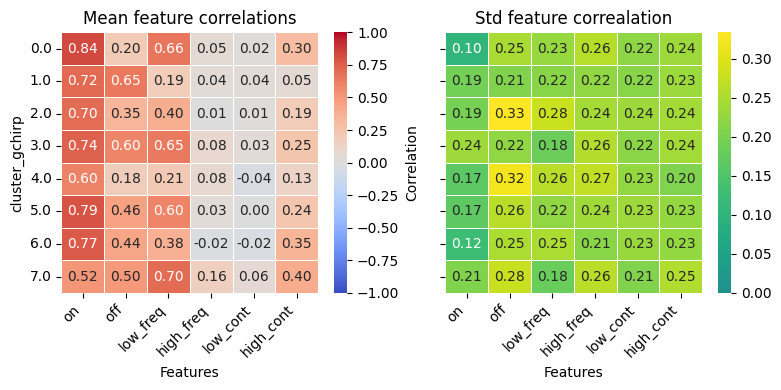

In [28]:
# Select the six columns to plot
columns_plot = df_mean_correlation.columns.drop("cluster_gchirp")
data_mean = df_mean_correlation[columns_plot]
data_std = df_std_correlation[columns_plot]

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.heatmap(
    data_mean,
    ax=ax[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation["cluster_gchirp"]
)

sns.heatmap(
    data_std,
    ax=ax[1],
    cmap="viridis",
    vmin=0,
    vmax=data_std.values.max(),
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    #cbar_kws={"label": "Std"},
    yticklabels=df_std_correlation["cluster_gchirp"]
)

ax[0].set_ylabel("cluster_gchirp")
ax[0].set_title("Mean feature correlations")
ax[1].set_title("Std feature correalation")

for i in ax:

    # Label axes
    i.set_xlabel("Features")
    i.set_xticklabels(columns_plot, rotation=45, ha="right")
    i.set_yticklabels(df_mean_correlation["cluster_gchirp"], rotation=0)

plt.tight_layout()
# plt.savefig(f"../plots/clustering/C1C2_feature_correlations_mean_heatmap_{current_date}.png",
#             dpi=300,
#             bbox_inches="tight")
plt.show()

# Continue for C1 / DETA/NO

In [29]:
df_detano.shape

(1926, 48)

In [30]:
n_rois_c1 = []
n_rois_no = []

for i in cluster_ids:

    df_cluster = df_detano[df_detano["cluster_gchirp"] == i]

    #n_rois.append(df_cluster.shape[0] / 2)

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_no_cluster = df_cluster[df_cluster["cond2"] == "DETANO"]

    n_rois_c1.append(df_c1_cluster.shape[0])
    n_rois_no.append(df_no_cluster.shape[0])
    
print(sum(n_rois_c1))
print(sum(n_rois_no))

696
696


In [31]:
corr_list = []

for i in cluster_ids:

    df_cluster = df_detano[df_detano["cluster_gchirp"] == i]

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_no_cluster = df_cluster[df_cluster["cond2"] == "DETANO"]

    max_end = max(end for _, end in features.values())

    len_c1 = df_c1_cluster[trace_col].apply(lambda x: len(np.asarray(x)))
    len_no = df_no_cluster[trace_col].apply(lambda x: len(np.asarray(x)))

    too_short = (len_c1 < max_end) | (len_no < max_end)

    if too_short.sum() > 0:
        raise ValueError("One of the traces is too short")

    key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

    # If roi_id was moved into the index in Cell 2, bring it back as a column
    c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
    no_k = df_no_cluster.reset_index() if roi_id_col is not None else df_no_cluster
    
    missing = [k for k in key_cols if k not in c1_k.columns or k not in no_k.columns]
    assert not missing, f"Missing key columns: {missing}"
    
    # Keys that are identical in both dataframes for every ROI are stored once;
    # keys that differ are stored as <key>_c1 and <key>_no
    differing = [k for k in key_cols
                 if not (c1_k[k].astype(str).values == no_k[k].astype(str).values).all()]
    shared = [k for k in key_cols if k not in differing]
    # print("Shared keys:   ", shared)
    # print("Differing keys:", differing)
    
    results = []
    for j in range(len(c1_k)):
        row1 = c1_k.iloc[j]
        row2 = no_k.iloc[j]
    
        rec = {k: row1[k] for k in shared}
        for k in differing:
            rec[f"{k}_c1"] = row1[k]
            rec[f"{k}_no"] = row2[k]
    
        rec.update(feature_correlations(row1[trace_col], row2[trace_col], features))
        results.append(rec)
    
    index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "no")]
    df_corr = pd.DataFrame(results).set_index(index_cols)
    df_corr_flat = df_corr.reset_index()
    
    assert df_corr.index.is_unique, "Primary keys do not uniquely identify ROIs!"
    df_corr_flat.head()

    corr_list.append(df_corr_flat)
df_correlation_no = pd.concat(corr_list, ignore_index=True)
print(df_correlation_no.shape)
df_correlation_no.head()

(696, 15)


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY2,RR,v,164,0.0,0.573850,-0.022286,-0.026509,0.095920,0.137113,-0.464097
1,Salomon,2025-09-08,2,1,XY2,RR,v,184,0.0,0.719981,-0.147137,0.025101,-0.035362,0.198239,-0.513977
2,Salomon,2025-09-08,2,1,XY8,RR,n,7,0.0,0.873413,0.630438,0.711151,-0.047379,0.160256,0.613815
3,Salomon,2025-09-08,2,1,XY8,RR,n,12,0.0,0.945290,0.764585,0.722611,-0.290592,-0.387871,0.564092
4,Salomon,2025-09-08,2,1,XY8,RR,n,13,0.0,0.948081,-0.262090,0.211958,-0.052803,-0.083206,-0.103321


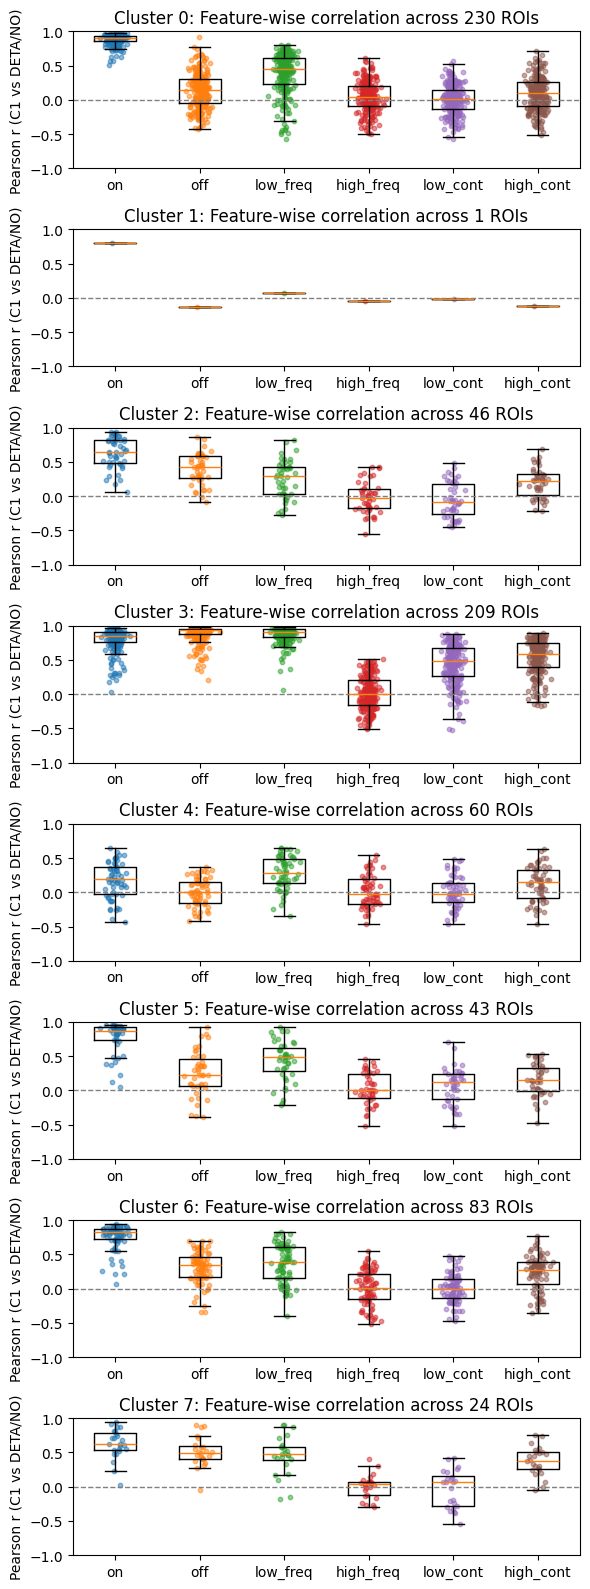

In [32]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(6, 2 * n_clusters))

for i in cluster_ids:

    df_correlation_cluster = df_correlation_no[df_correlation_no["cluster_gchirp"] == i]

    data = [df_correlation_cluster[f].dropna().values for f in features]
    axs[i].boxplot(data, tick_labels=list(features), showfliers=False)
    
    for j, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.06, size=len(d))
        axs[i].scatter(np.full(len(d), j) + jitter, d, s=10, alpha=0.5)
    
    axs[i].axhline(0, color="grey", linestyle="--", linewidth=1)
    axs[i].set_ylabel("Pearson r (C1 vs DETA/NO)")
    axs[i].set_title(f"Cluster {i}: Feature-wise correlation across {len(df_correlation_cluster)} ROIs")
    axs[i].set_ylim(-1,1)

plt.tight_layout()
# plt.savefig(f"../plots/clustering/C1NO_feature_correlations_boxplot_{current_date}.png",
#             dpi=300,
#             bbox_inches="tight")
plt.show()

In [33]:
df_correlation_cluster = df_correlation_no[df_correlation_no["cluster_gchirp"] == 0]
df_correlation_cluster

,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY2,RR,v,164,0.0,0.573850,-0.022286,-0.026509,0.095920,0.137113,-0.464097
1,Salomon,2025-09-08,2,1,XY2,RR,v,184,0.0,0.719981,-0.147137,0.025101,-0.035362,0.198239,-0.513977
2,Salomon,2025-09-08,2,1,XY8,RR,n,7,0.0,0.873413,0.630438,0.711151,-0.047379,0.160256,0.613815
3,Salomon,2025-09-08,2,1,XY8,RR,n,12,0.0,0.945290,0.764585,0.722611,-0.290592,-0.387871,0.564092
4,Salomon,2025-09-08,2,1,XY8,RR,n,13,0.0,0.948081,-0.262090,0.211958,-0.052803,-0.083206,-0.103321
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,Salomon,2025-10-23,2,1,XY6,RR,n,94,0.0,0.870028,0.358747,-0.020993,-0.137503,0.074541,0.064275
226,Salomon,2025-10-23,2,1,XY6,RR,n,100,0.0,0.909014,0.144459,0.543140,0.083010,0.049621,0.112128
227,Salomon,2025-10-23,2,1,XY6,RR,n,103,0.0,0.863260,-0.090885,0.116450,-0.007399,0.366748,-0.165343
228,Salomon,2025-10-23,2,1,XY6,RR,n,111,0.0,0.847543,-0.104272,-0.302836,-0.018023,0.066763,-0.120360


In [34]:
columns

['cluster_gchirp',
 'on',
 'off',
 'low_freq',
 'high_freq',
 'low_cont',
 'high_cont']

In [35]:
mean_correlation_no = []
std_correlation_no = []

for row, i in enumerate(cluster_ids):

    df_correlation_cluster = df_correlation_no[
        df_correlation_no["cluster_gchirp"] == i
    ]

    mean_corr_cluster = df_correlation_cluster[columns].mean(axis=0)
    std_corr_cluster = df_correlation_cluster[columns].std(axis=0)

    # Convert to DataFrames with one row
    heatmap_mean_cluster = pd.DataFrame(
        [mean_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    heatmap_std_cluster = pd.DataFrame(
        [std_corr_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    mean_correlation_no.append(heatmap_mean_cluster)
    std_correlation_no.append(heatmap_std_cluster)

df_mean_correlation_no = pd.concat(mean_correlation_no)
df_mean_correlation_no = df_mean_correlation_no.reset_index(drop=True)

df_std_correlation_no = pd.concat(std_correlation_no)
df_std_correlation_no = df_std_correlation_no.reset_index(drop=True)


In [36]:
df_mean_correlation_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.883330,0.132484,0.389980,0.051316,0.003864,0.095838
1,1.0,0.804379,-0.135436,0.075909,-0.044454,-0.011818,-0.116509
2,2.0,0.627609,0.397396,0.251984,-0.023365,-0.060521,0.194821
3,3.0,0.798789,0.880883,0.867264,0.018271,0.441308,0.546464
4,4.0,0.175527,-0.000138,0.281472,0.021697,0.008735,0.122492
5,5.0,0.761212,0.252879,0.430870,0.029874,0.068440,0.151499
6,6.0,0.759758,0.308167,0.361178,0.010882,-0.003219,0.230827
7,7.0,0.625912,0.512371,0.459845,0.001421,-0.030914,0.374449


In [37]:
data_std_no = df_std_correlation_no[columns]
np.nanmax(data_std_no)

0.3210796859663758

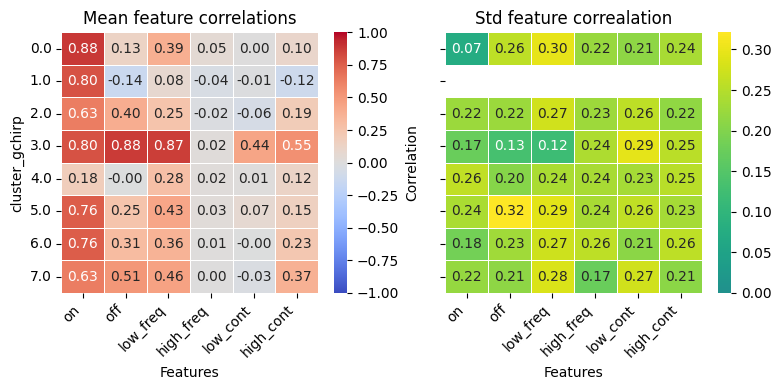

In [38]:
# Select the six columns to plot
columns_plot = df_mean_correlation_no.columns.drop("cluster_gchirp")
data_mean_no = df_mean_correlation_no[columns_plot]
data_std_no = df_std_correlation_no[columns_plot]

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.heatmap(
    data_mean_no,
    ax=ax[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation_no["cluster_gchirp"]
)

sns.heatmap(
    data_std_no,
    ax=ax[1],
    cmap="viridis",
    vmin=0,
    vmax=np.nanmax(data_std_no),
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    #cbar_kws={"label": "Std"},
    yticklabels=df_std_correlation_no["cluster_gchirp"]
)

ax[0].set_ylabel("cluster_gchirp")
ax[0].set_title("Mean feature correlations")
ax[1].set_title("Std feature correalation")

for i in ax:

    # Label axes
    i.set_xlabel("Features")
    i.set_xticklabels(columns_plot, rotation=45, ha="right")
    i.set_yticklabels(df_mean_correlation_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
# plt.savefig(f"../plots/clustering/C1NO_feature_correlations_mean_heatmap_{current_date}.png",
#             dpi=300,
#             bbox_inches="tight")
plt.show()

# C2 / DETA/NO

- to inspect whether differences appear in C2 / DETA/NO the correlation matrices will be divided with one another

In [40]:
df_mean_correlation

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.835199,0.196062,0.660619,0.053445,0.022269,0.301533
1,1.0,0.717334,0.651077,0.185503,0.043293,0.039392,0.049828
2,2.0,0.696134,0.348780,0.396043,0.005536,0.011177,0.192573
3,3.0,0.742760,0.600421,0.648119,0.081492,0.033867,0.249707
4,4.0,0.602790,0.175840,0.212679,0.077769,-0.036322,0.128935
5,5.0,0.791508,0.455530,0.599067,0.034894,0.001594,0.239220
6,6.0,0.767275,0.439278,0.381487,-0.021218,-0.024426,0.353411
7,7.0,0.515764,0.496309,0.696637,0.162209,0.062414,0.402498


In [41]:
df_mean_correlation_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,0.883330,0.132484,0.389980,0.051316,0.003864,0.095838
1,1.0,0.804379,-0.135436,0.075909,-0.044454,-0.011818,-0.116509
2,2.0,0.627609,0.397396,0.251984,-0.023365,-0.060521,0.194821
3,3.0,0.798789,0.880883,0.867264,0.018271,0.441308,0.546464
4,4.0,0.175527,-0.000138,0.281472,0.021697,0.008735,0.122492
5,5.0,0.761212,0.252879,0.430870,0.029874,0.068440,0.151499
6,6.0,0.759758,0.308167,0.361178,0.010882,-0.003219,0.230827
7,7.0,0.625912,0.512371,0.459845,0.001421,-0.030914,0.374449


In [43]:
columns_plot

Index(['on', 'off', 'low_freq', 'high_freq', 'low_cont', 'high_cont'], dtype='object')

In [45]:
np.abs(df_mean_correlation[columns_plot]) / np.abs(df_mean_correlation_no[columns_plot])

,on,off,low_freq,high_freq,low_cont,high_cont
0,0.945511,1.479892,1.693981,1.041492,5.762834,3.146292
1,0.891787,4.807282,2.443750,0.973895,3.333141,0.427673
2,1.109184,0.877663,1.571698,0.236925,0.184673,0.988464
3,0.929857,0.681612,0.747314,4.460277,0.076741,0.456951
4,3.434173,1274.293860,0.755596,3.584399,4.158018,1.052599
5,1.039799,1.801376,1.390366,1.168050,0.023286,1.579015
6,1.009894,1.425453,1.056231,1.949786,7.587905,1.531064
7,0.824020,0.968651,1.514941,114.118644,2.018976,1.074906


In [48]:
df_mean_correlation_c2_no = df_mean_correlation[columns_plot] - df_mean_correlation_no[columns_plot]
df_mean_correlation_c2_no

,on,off,low_freq,high_freq,low_cont,high_cont
0,-0.048132,0.063578,0.270639,0.002129,0.018404,0.205696
1,-0.087044,0.786513,0.109594,0.087747,0.051211,0.166337
2,0.068525,-0.048616,0.144059,0.028901,0.071697,-0.002248
3,-0.056029,-0.280463,-0.219145,0.063222,-0.407441,-0.296757
4,0.427263,0.175978,-0.068793,0.056073,-0.045057,0.006443
5,0.030296,0.202651,0.168197,0.005020,-0.066847,0.087720
6,0.007517,0.131111,0.020309,-0.032100,-0.021207,0.122584
7,-0.110148,-0.016062,0.236793,0.160788,0.093328,0.028049


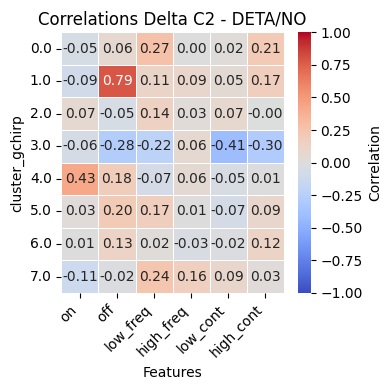

In [53]:
# Select the six columns to plot
#columns_plot = df_mean_correlation_no.columns.drop("cluster_gchirp")
data_matrix = df_mean_correlation_c2_no

# Create heatmap
fig, ax = plt.subplots(1, 1, figsize=(4, 4), sharey=True)

sns.heatmap(
    data_matrix,
    ax=ax,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Correlation"},
    yticklabels=df_mean_correlation_no["cluster_gchirp"]
)

ax.set_ylabel("cluster_gchirp")
ax.set_title("Correlations Delta C2 - DETA/NO")

ax.set_xlabel("Features")
ax.set_xticklabels(columns_plot, rotation=45, ha="right")
ax.set_yticklabels(df_mean_correlation_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C2NO_feature_correlations_mean_heatmap_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()